[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DEDJIABDOUL/omicaa-lab-machine-learning-bioinformatics/blob/main/notebooks/06_deep_learning_tensorflow.ipynb)

# Notebook 06 : introduction opérationnelle au deep learning avec TensorFlow et Keras

**Omicaa Lab | Machine Learning et Deep Learning pour les biologistes** | Auteur : DEDJI ABDOUL BATINOU

## Introduction scientifique

Un réseau de neurones est une composition de fonctions simples, paramétrées par des poids, dont l'apprentissage consiste à ajuster ces poids pour réduire une fonction de perte. Il n'est pas une amélioration automatique du machine learning classique : sur des données tabulaires de quelques centaines d'observations, il rivalise rarement avec une régression logistique bien réglée. Ce notebook en explique les mécanismes sur un cas minimal, puis construit un réseau dense pour le jeu Breast Cancer Wisconsin selon un protocole compatible avec les notebooks précédents.

## Objectifs techniques

1. Manipuler des tenseurs et comprendre forme, type et opérations.
2. Calculer à la main un neurone, une fonction de perte et un gradient, puis les vérifier avec TensorFlow.
3. Construire, compiler, entraîner et évaluer un réseau dense Keras.
4. Diagnostiquer le surapprentissage à partir des courbes d'apprentissage et le contrôler (dropout, arrêt anticipé).
5. Comparer un réseau et un modèle classique dans des conditions d'évaluation compatibles.

## Prérequis

* Notebooks 04 et 05 terminés.
* Exécution sur CPU suffisante : aucun GPU n'est requis.

## Résultat attendu

Un réseau dense entraîné avec arrêt anticipé, évalué une fois sur le test réservé, comparé à la régression logistique entraînée sur les mêmes données, puis sauvegardé et rechargé.

## 1. Contrôle de l'environnement

In [1]:
import sys, platform, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import os, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"      # réduit les messages techniques de TensorFlow
from pathlib import Path
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.3
NumPy       : 2.4.4
pandas      : 3.0.2
Matplotlib  : 3.10.8
scikit-learn: 1.8.0


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)       # fixe les graines Python, NumPy et TensorFlow
print("TensorFlow :", tf.__version__, "| Keras :", keras.__version__)
print("périphériques :", [d.device_type for d in tf.config.list_physical_devices()])

import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

FIG, RES, MOD = Path("figures"), Path("results"), Path("models")
for d in (FIG, RES, MOD): d.mkdir(exist_ok=True)
ROUGE, CYAN, NOIR, GRIS = "#FF0000", "#0097B2", "#000000", "#8A8A8A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9.5})
JOURNAL = {"notebook": "06", "graine": SEED, "tensorflow": tf.__version__, "sklearn": sklearn.__version__}

I0000 00:00:1791603849.760182   13990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791603851.379300   13990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow : 2.21.0 | Keras : 3.15.1
périphériques : ['CPU']


## 2. Quand le deep learning est-il justifié ?

Le deep learning excelle lorsque la structure des données est riche et que le volume permet d'apprendre des représentations :

* **images** (histopathologie, microscopie) : réseaux convolutifs ;
* **séquences** (ADN, ARN, protéines) : réseaux convolutifs 1D, récurrents ou à attention ;
* **grands volumes** de données (dizaines de milliers d'observations ou plus) ;
* données **multimodales** ou apprentissage de représentations réutilisables.

Il est en revanche rarement avantageux sur des **tableaux de quelques centaines de lignes** : plus de paramètres que de données, hyperparamètres nombreux, résultats plus variables, interprétation plus difficile. Ce notebook a donc une visée de **compréhension des mécanismes** : on ne s'attend pas à ce que le réseau batte la régression logistique sur ce jeu.

## 3. Tenseurs

Un **tenseur** est un tableau multidimensionnel de nombres, de forme et de type définis. Un scalaire est un tenseur de rang 0, un vecteur de rang 1, une matrice de rang 2. Un lot d'observations d'une matrice $X \in \mathbb{R}^{n \times p}$ est un tenseur de rang 2 de forme `(n, p)`. Les tenseurs TensorFlow sont proches des tableaux NumPy mais peuvent être différenciés automatiquement.

In [3]:
scalaire = tf.constant(3.5)
vecteur = tf.constant([1.0, 2.0, 3.0])
matrice = tf.constant([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
for nom, t in [("scalaire", scalaire), ("vecteur", vecteur), ("matrice", matrice)]:
    print(f"{nom:9s} rang={tf.rank(t).numpy()} forme={tuple(t.shape)} type={t.dtype.name}")

W = tf.constant([[0.5], [-1.0]])
print("produit matriciel (3,2) x (2,1) ->", tuple(tf.matmul(matrice, W).shape))
print("conversion NumPy :", type(matrice.numpy()).__name__, "| et retour :", tf.convert_to_tensor(np.eye(2, dtype="float32")).dtype.name)

scalaire  rang=0 forme=() type=float32
vecteur   rang=1 forme=(3,) type=float32
matrice   rang=2 forme=(3, 2) type=float32
produit matriciel (3,2) x (2,1) -> (3, 1)
conversion NumPy : ndarray | et retour : float32


Keras travaille par défaut en `float32`. Fournir un tableau NumPy en `float64` fonctionne mais provoque une conversion ; on convertit explicitement pour maîtriser le type.

## 4. Un neurone, à la main

Un neurone calcule une somme pondérée de ses entrées, ajoute un **biais**, puis applique une **fonction d'activation** :

$$z = w^\top x + b, \qquad \hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Les poids $w$ et le biais $b$ sont les **paramètres** à apprendre. La sigmoïde transforme $z \in \mathbb{R}$ en une valeur entre 0 et 1 interprétable comme une probabilité. Sans fonction d'activation non linéaire, un empilement de couches serait équivalent à une seule transformation linéaire : l'activation (par exemple ReLU, $\max(0, z)$) donne au réseau sa capacité à représenter des relations non linéaires.

In [4]:
x = np.array([1.2, -0.5, 0.8])         # trois mesures (valeurs fictives)
w = np.array([0.4, 0.9, -0.3])
b = 0.1

z = w @ x + b
y_hat = 1 / (1 + np.exp(-z))
print(f"z = {z:.4f}  ->  probabilité = {y_hat:.4f}")
assert 0 < y_hat < 1
assert np.isclose(y_hat, tf.sigmoid(tf.constant(z)).numpy())

z = -0.1100  ->  probabilité = 0.4725


## 5. Fonction de perte

La **perte** mesure l'écart entre la prédiction et la vérité. Pour une classification binaire on utilise l'entropie croisée binaire :

$$L = -\frac{1}{n}\sum_{i=1}^{n}\left[ y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right]$$

Elle pénalise lourdement une prédiction confiante et fausse : prédire 0,01 pour une tumeur maligne coûte bien plus que prédire 0,4.

In [5]:
y_vrai = np.array([1, 0, 1, 0])
p_pred = np.array([0.9, 0.2, 0.4, 0.01])
perte_main = -np.mean(y_vrai * np.log(p_pred) + (1 - y_vrai) * np.log(1 - p_pred))
perte_keras = keras.losses.BinaryCrossentropy()(y_vrai.astype("float32"), p_pred.astype("float32")).numpy()
print("perte à la main :", round(perte_main, 5), "| Keras :", round(float(perte_keras), 5))
assert np.isclose(perte_main, perte_keras, atol=1e-5)
print("coût d'une erreur confiante : -log(0.01) =", round(-np.log(0.01), 3), "contre -log(0.4) =", round(-np.log(0.4), 3))

perte à la main : 0.31371 | Keras : 0.31371
coût d'une erreur confiante : -log(0.01) = 4.605 contre -log(0.4) = 0.916


## 6. Gradient, descente de gradient et rétropropagation

Le **gradient** de la perte par rapport à un poids indique dans quel sens et avec quelle intensité la perte varie quand ce poids change. Pour réduire la perte, on déplace chaque poids dans la direction opposée au gradient :

$$w \leftarrow w - \eta \, \frac{\partial L}{\partial w}$$

où $\eta$ est le **taux d'apprentissage**, un hyperparamètre. Dans un réseau à plusieurs couches, la **rétropropagation** applique la règle de dérivation des fonctions composées : le gradient de la perte est propagé de la sortie vers l'entrée, couche après couche, ce qui fournit efficacement le gradient pour chacun des poids. TensorFlow le calcule automatiquement avec `GradientTape`.

**Vérification sur un neurone.** Pour la sigmoïde associée à l'entropie croisée, le gradient analytique est $\frac{1}{n} X^\top (\hat{y} - y)$. On le compare au gradient automatique.

In [6]:
rng = np.random.default_rng(SEED)
Xt = rng.normal(size=(6, 3)).astype("float32")
yt = np.array([1, 0, 1, 1, 0, 0], dtype="float32")

w_tf = tf.Variable(rng.normal(size=(3,)).astype("float32"))
b_tf = tf.Variable(0.0)
with tf.GradientTape() as tape:
    p = tf.sigmoid(tf.linalg.matvec(Xt, w_tf) + b_tf)
    perte = keras.losses.BinaryCrossentropy()(yt, p)
g_w, g_b = tape.gradient(perte, [w_tf, b_tf])

g_analytique = Xt.T @ (p.numpy() - yt) / len(yt)
print("gradient automatique :", g_w.numpy().round(5))
print("gradient analytique  :", g_analytique.round(5))
assert np.allclose(g_w.numpy(), g_analytique, atol=1e-5)

gradient automatique : [ 0.14296 -0.13786 -0.3336 ]
gradient analytique  : [ 0.14296 -0.13786 -0.3336 ]


**Descente de gradient.** Une boucle d'entraînement répète : calculer la perte, calculer le gradient, mettre à jour les poids. On l'écrit explicitement sur un jeu fictif de deux nuages séparables.

In [7]:
rng = np.random.default_rng(SEED)
Xa = np.vstack([rng.normal(-1, 0.8, size=(40, 2)), rng.normal(1, 0.8, size=(40, 2))]).astype("float32")
ya = np.array([0] * 40 + [1] * 40, dtype="float32")
w_d, b_d = tf.Variable(tf.zeros(2)), tf.Variable(0.0)
eta = 0.5
for etape in range(201):
    with tf.GradientTape() as tape:
        p = tf.sigmoid(tf.linalg.matvec(Xa, w_d) + b_d)
        perte = keras.losses.BinaryCrossentropy()(ya, p)
    gw, gb = tape.gradient(perte, [w_d, b_d])
    w_d.assign_sub(eta * gw); b_d.assign_sub(eta * gb)
    if etape in (0, 10, 50, 200):
        acc = np.mean((p.numpy() > 0.5) == ya)
        print(f"étape {etape:3d} | perte = {perte.numpy():.4f} | accuracy = {acc:.3f}")
assert perte.numpy() < 0.4

étape   0 | perte = 0.6931 | accuracy = 0.500
étape  10 | perte = 0.1998 | accuracy = 0.988


étape  50 | perte = 0.0945 | accuracy = 0.988


étape 200 | perte = 0.0533 | accuracy = 0.988


En pratique, on n'utilise pas tout le jeu de données à chaque étape : on le découpe en **lots** (*mini-batches*, par exemple 32 observations). Une **époque** est un passage complet sur les données d'entraînement. L'optimiseur **Adam**, utilisé plus bas, adapte le pas de chaque poids à partir de l'historique des gradients.

## 7. Données et protocole

Le protocole est compatible avec celui du notebook 05 : même jeu, même partition entraînement et test (mêmes graines), même classe positive (maligne). Pour l'**arrêt anticipé**, on extrait de l'entraînement un jeu de **validation** (20 %). Le test reste intact jusqu'à la section 11.

* Le `StandardScaler` est ajusté sur les seules données d'**ajustement** (entraînement moins validation), puis appliqué à la validation et au test.
* Les entrées sont converties en `float32`.

In [8]:
bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = (bunch.target == 0).astype(int).rename("maligne")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

scaler = StandardScaler().fit(X_fit)
A_fit, A_val, A_test = [scaler.transform(d).astype("float32") for d in (X_fit, X_val, X_test)]
b_fit, b_val, b_test = [v.values.astype("float32") for v in (y_fit, y_val, y_test)]

print("ajustement :", A_fit.shape, "| validation :", A_val.shape, "| test (réservé) :", A_test.shape)
assert A_fit.shape[1] == 30 and A_fit.dtype == np.float32
assert set(X_fit.index).isdisjoint(X_val.index) and set(X_fit.index).isdisjoint(X_test.index)
assert abs(A_fit.mean(axis=0)).max() < 1e-4        # le scaler est centré sur l'ajustement
print("parts malignes :", b_fit.mean().round(3), b_val.mean().round(3), b_test.mean().round(3))

ajustement : (364, 30) | validation : (91, 30) | test (réservé) : (114, 30)
parts malignes : 0.374 0.374 0.368


## 8. Définir, compiler et entraîner un réseau dense

**Architecture.** Entrée de 30 valeurs, deux couches cachées (16 puis 8 neurones, activation ReLU), un `Dropout`, et une sortie à un neurone sigmoïde.

* `Dense(16)` : chaque neurone calcule une somme pondérée des 30 entrées plus un biais : $30 \times 16 + 16 = 496$ paramètres.
* `Dropout(0.2)` : pendant l'entraînement seulement, 20 % des activations sont mises à zéro au hasard, ce qui empêche le réseau de dépendre excessivement de neurones particuliers. C'est une régularisation.
* `Dense(1, activation="sigmoid")` : sortie interprétée comme la probabilité d'une tumeur maligne.

**Compilation.** On choisit l'optimiseur (Adam, taux d'apprentissage 0,001), la perte (entropie croisée binaire) et des métriques de suivi.

**Arrêt anticipé.** `EarlyStopping` surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant `patience` époques, puis restaure les meilleurs poids.

In [9]:
def construire_reseau(unites=(16, 8), dropout=0.2, lr=1e-3):
    modele = keras.Sequential([layers.Input(shape=(30,))] +
                              [layers.Dense(u, activation="relu") for u in unites[:1]] +
                              ([layers.Dropout(dropout)] if dropout > 0 else []) +
                              [layers.Dense(u, activation="relu") for u in unites[1:]] +
                              [layers.Dense(1, activation="sigmoid")])
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return modele

keras.utils.set_random_seed(SEED)
reseau = construire_reseau()
reseau.summary()
nb_params = reseau.count_params()
assert nb_params == 30 * 16 + 16 + 16 * 8 + 8 + 8 + 1
print("nombre de paramètres :", nb_params, "pour", len(A_fit), "observations d'ajustement")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

nombre de paramètres : 641 pour 364 observations d'ajustement


In [10]:
arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
historique = reseau.fit(A_fit, b_fit, validation_data=(A_val, b_val), epochs=300, batch_size=32,
                        callbacks=[arret], verbose=0)
h = historique.history
meilleure_epoque = int(np.argmin(h["val_loss"])) + 1
print(f"époques exécutées : {len(h['loss'])} | meilleure époque (perte de validation minimale) : {meilleure_epoque}")
print(f"perte entraînement = {h['loss'][meilleure_epoque-1]:.4f} | perte validation = {h['val_loss'][meilleure_epoque-1]:.4f}")
print(f"AUC validation = {h['val_auc'][meilleure_epoque-1]:.4f} | accuracy validation = {h['val_accuracy'][meilleure_epoque-1]:.4f}")
assert len(h["loss"]) < 300, "l'arrêt anticipé n'a pas été déclenché"

époques exécutées : 229 | meilleure époque (perte de validation minimale) : 209
perte entraînement = 0.0959 | perte validation = 0.1503
AUC validation = 0.9830 | accuracy validation = 0.9670


**Un pas d'entraînement, vu de l'intérieur.** On calcule le gradient de la perte sur un lot pour inspecter la rétropropagation : chaque tenseur de poids reçoit un gradient de même forme.

In [11]:
xb, yb = A_fit[:32], b_fit[:32]
with tf.GradientTape() as tape:
    pred = reseau(xb, training=True)
    perte = keras.losses.BinaryCrossentropy()(yb.reshape(-1, 1), pred)
grads = tape.gradient(perte, reseau.trainable_variables)
for v, g in zip(reseau.trainable_variables, grads):
    assert tuple(g.shape) == tuple(v.shape)
    print(f"{v.path if hasattr(v, 'path') else v.name:28s} forme {str(tuple(v.shape)):9s} norme du gradient = {float(tf.norm(g)):.4f}")

sequential/dense/kernel      forme (30, 16)  norme du gradient = 0.0361
sequential/dense/bias        forme (16,)     norme du gradient = 0.0110
sequential/dense_1/kernel    forme (16, 8)   norme du gradient = 0.0071
sequential/dense_1/bias      forme (8,)      norme du gradient = 0.0042
sequential/dense_2/kernel    forme (8, 1)    norme du gradient = 0.0049
sequential/dense_2/bias      forme (1,)      norme du gradient = 0.0667


## 9. Courbes d'apprentissage et surapprentissage

Les courbes de perte d'entraînement et de validation sont l'instrument de diagnostic principal :

* les deux baissent ensemble : le modèle apprend ;
* la perte d'entraînement baisse mais celle de validation remonte : **surapprentissage**, le modèle mémorise ;
* les deux restent élevées : sous-apprentissage, le modèle est trop simple ou mal entraîné.

Pour **provoquer** un surapprentissage, on entraîne un réseau volumineux (trois couches de 128 neurones), sans dropout, sans arrêt anticipé, pendant 200 époques.

réseau volumineux : 37121 paramètres
perte de validation minimale = 0.0580 à l'époque 7
perte de validation finale   = 0.1778 à l'époque 200 | perte d'entraînement finale = 0.00000


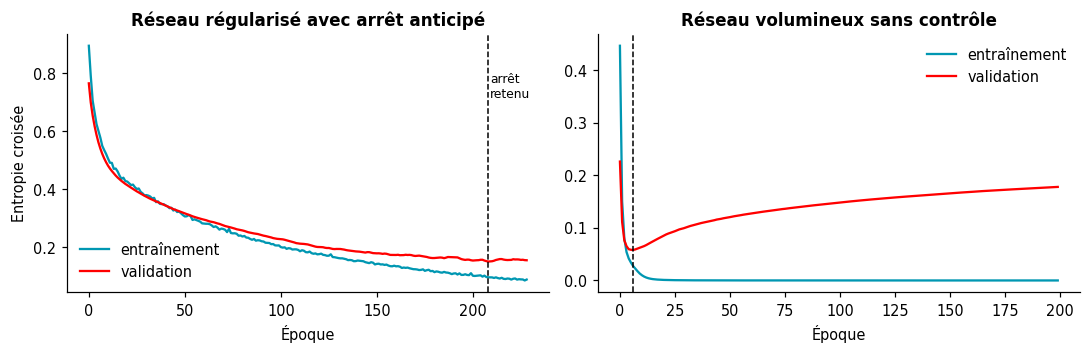

In [12]:
keras.utils.set_random_seed(SEED)
gros = keras.Sequential([layers.Input(shape=(30,)), layers.Dense(128, activation="relu"),
                         layers.Dense(128, activation="relu"), layers.Dense(128, activation="relu"),
                         layers.Dense(1, activation="sigmoid")])
gros.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy", keras.metrics.AUC(name="auc")])
h_gros = gros.fit(A_fit, b_fit, validation_data=(A_val, b_val), epochs=200, batch_size=32, verbose=0).history

i_min = int(np.argmin(h_gros["val_loss"]))
print("réseau volumineux :", gros.count_params(), "paramètres")
print(f"perte de validation minimale = {h_gros['val_loss'][i_min]:.4f} à l'époque {i_min + 1}")
print(f"perte de validation finale   = {h_gros['val_loss'][-1]:.4f} à l'époque 200 | perte d'entraînement finale = {h_gros['loss'][-1]:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=False)
axes[0].plot(h["loss"], color=CYAN, label="entraînement"); axes[0].plot(h["val_loss"], color=ROUGE, label="validation")
axes[0].axvline(meilleure_epoque - 1, color=NOIR, ls="--", lw=1); axes[0].text(meilleure_epoque, max(h["loss"]) * 0.8, "arrêt\nretenu", fontsize=8)
axes[0].set_title("Réseau régularisé avec arrêt anticipé"); axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Entropie croisée"); axes[0].legend(frameon=False)
axes[1].plot(h_gros["loss"], color=CYAN, label="entraînement"); axes[1].plot(h_gros["val_loss"], color=ROUGE, label="validation")
axes[1].axvline(i_min, color=NOIR, ls="--", lw=1)
axes[1].set_title("Réseau volumineux sans contrôle"); axes[1].set_xlabel("Époque"); axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_courbes_dl.png", dpi=170, bbox_inches="tight")
plt.show()
JOURNAL["reseau_regularise"] = {"parametres": int(nb_params), "epoques_executees": len(h["loss"]), "meilleure_epoque": meilleure_epoque,
                                "val_loss": round(float(h["val_loss"][meilleure_epoque - 1]), 4), "val_auc": round(float(h["val_auc"][meilleure_epoque - 1]), 4)}
JOURNAL["reseau_volumineux"] = {"parametres": int(gros.count_params()), "val_loss_min": round(float(h_gros["val_loss"][i_min]), 4), "epoque_min": i_min + 1,
                                "val_loss_finale": round(float(h_gros["val_loss"][-1]), 4), "train_loss_finale": round(float(h_gros["loss"][-1]), 6)}

Dans le réseau volumineux, la perte d'entraînement tend vers zéro tandis que la perte de validation, après avoir atteint un minimum, **remonte** : l'entraînement prolongé dégrade la généralisation. L'arrêt anticipé revient à s'arrêter à ce minimum. Ce diagnostic ne se lit que sur les courbes : l'accuracy d'entraînement seule ne le révèle pas.

## 10. Variabilité due à la graine

Un réseau est initialisé au hasard : deux entraînements avec des graines différentes donnent des modèles différents. Avant de comparer des modèles, il faut connaître cette variabilité. On la mesure sur le **jeu de validation** (jamais sur le test) en entraînant le même réseau avec cinq graines.

In [13]:
auc_val, loss_val = [], []
for graine in range(5):
    keras.utils.set_random_seed(graine)
    r = construire_reseau()
    hh = r.fit(A_fit, b_fit, validation_data=(A_val, b_val), epochs=300, batch_size=32, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)]).history
    k = int(np.argmin(hh["val_loss"]))
    auc_val.append(hh["val_auc"][k]); loss_val.append(hh["val_loss"][k])
    print(f"graine {graine} | époque retenue {k + 1:3d} | perte validation {hh['val_loss'][k]:.4f} | AUC validation {hh['val_auc'][k]:.4f}")
print(f"AUC de validation : moyenne {np.mean(auc_val):.4f}, écart type {np.std(auc_val):.4f}")
JOURNAL["variabilite_graines_val"] = {"auc_moy": round(float(np.mean(auc_val)), 4), "auc_std": round(float(np.std(auc_val)), 4),
                                      "auc_min": round(float(np.min(auc_val)), 4), "auc_max": round(float(np.max(auc_val)), 4)}

graine 0 | époque retenue  45 | perte validation 0.0778 | AUC validation 0.9928


graine 1 | époque retenue  63 | perte validation 0.0781 | AUC validation 0.9938


graine 2 | époque retenue  62 | perte validation 0.0803 | AUC validation 0.9943


graine 3 | époque retenue 216 | perte validation 0.1428 | AUC validation 0.9856


graine 4 | époque retenue  50 | perte validation 0.0794 | AUC validation 0.9923
AUC de validation : moyenne 0.9917, écart type 0.0032


**Précision importante.** La graine 42 du réseau principal (section 8) a été fixée **avant** tout résultat, comme graine par défaut de tout le parcours. Elle ne doit pas être remplacée après coup par une graine plus favorable : ce serait une sélection sur les résultats. Si, comme ici, le réseau principal se révèle plus lent ou moins performant que la plupart des autres graines, on le rapporte tel quel et on s'appuie sur la **distribution** des cinq graines pour juger de la variabilité du modèle.

## 11. Évaluation finale et comparaison compatible

Le réseau retenu est celui de la section 8 (graine 42), figé. Il est évalué **une fois** sur le test.

**Condition de comparabilité.** Le réseau est ajusté sur 80 % de l'entraînement (`X_fit`) car 20 % servent à l'arrêt anticipé. La régression logistique de référence est donc ajustée sur **ce même `X_fit`**, avec le même `StandardScaler` et l'hyperparamètre `C = 1` retenu par validation croisée au notebook 05 (choix indépendant du test). Les deux modèles voient les mêmes données d'ajustement et sont évalués sur le même test. Comparer ce réseau au modèle du notebook 05, ajusté sur 100 % de l'entraînement, ne serait pas équitable.

In [14]:
proba_nn = reseau.predict(A_test, verbose=0).ravel()
lr = LogisticRegression(C=1.0, max_iter=1000).fit(scaler.transform(X_fit), y_fit)
proba_lr = lr.predict_proba(A_test)[:, 1]

def metriques(vrai, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    return {"accuracy": accuracy_score(vrai, pred), "precision": precision_score(vrai, pred, zero_division=0),
            "recall": recall_score(vrai, pred, zero_division=0), "f1": f1_score(vrai, pred, zero_division=0),
            "roc_auc": roc_auc_score(vrai, proba)}

tab = pd.DataFrame({"Réseau dense (Keras)": metriques(y_test, proba_nn), "Régression logistique (même ajustement)": metriques(y_test, proba_lr)})
print(tab.round(3))
for nom, p in [("réseau", proba_nn), ("régression logistique", proba_lr)]:
    vn, fp, fn, vp = confusion_matrix(y_test, (p >= 0.5).astype(int)).ravel()
    print(f"{nom:22s} VN={vn} FP={fp} FN={fn} VP={vp}")
assert proba_nn.shape == (len(X_test),) and ((proba_nn >= 0) & (proba_nn <= 1)).all()
JOURNAL["test"] = {"reseau": {k: round(float(v), 4) for k, v in tab.iloc[:, 0].items()},
                   "logreg_meme_ajustement": {k: round(float(v), 4) for k, v in tab.iloc[:, 1].items()}}

           Réseau dense (Keras)  Régression logistique (même ajustement)
accuracy                  0.974                                    0.982
precision                 0.976                                    0.976
recall                    0.952                                    0.976
f1                        0.964                                    0.976
roc_auc                   0.987                                    0.996
réseau                 VN=71 FP=1 FN=2 VP=40
régression logistique  VN=71 FP=1 FN=1 VP=41


**Interprétation.** Avec 114 observations de test, quelques observations suffisent à inverser un classement : les deux modèles sont **statistiquement indiscernables** sur ce test. On n'en conclut pas que l'un est supérieur, on constate que le réseau, plus complexe, n'apporte pas de gain démontrable. C'est le résultat attendu pour un tableau de cette taille.

## 12. Sauvegarde et rechargement

In [15]:
reseau.save(MOD / "reseau_dense.keras")
joblib.dump(scaler, MOD / "scaler_reseau.joblib")          # le réseau n'est utilisable qu'avec le même scaler

reseau2 = keras.models.load_model(MOD / "reseau_dense.keras")
scaler2 = joblib.load(MOD / "scaler_reseau.joblib")
proba_rechargee = reseau2.predict(scaler2.transform(X_test).astype("float32"), verbose=0).ravel()
assert np.allclose(proba_rechargee, proba_nn, atol=1e-6)
print("modèle et scaler rechargés : probabilités identiques. Exemple :", proba_rechargee[:3].round(4), "| vérité :", y_test.values[:3])
(RES / "nb06.json").write_text(json.dumps(JOURNAL, ensure_ascii=False, indent=2))

modèle et scaler rechargés : probabilités identiques. Exemple : [0.1293 1.     0.1293] | vérité : [0 1 0]


854

## 13. Limites

* Le jeu est petit et tabulaire : le réseau n'est pas le bon outil, il sert à illustrer les mécanismes.
* Le résultat d'un réseau dépend de la graine, de l'architecture, du taux d'apprentissage et de la patience. Ces choix ont été faits ici sans recherche exhaustive.
* Le déterminisme complet entre machines n'est pas garanti : les bibliothèques numériques peuvent différer légèrement selon le processeur et la version de TensorFlow.
* Les probabilités d'un réseau ne sont pas nécessairement calibrées.

## 14. Exercices progressifs

**Exercice 1.** Calculez à la main le nombre de paramètres d'un réseau `30 -> 32 -> 16 -> 1` puis vérifiez avec Keras.

*Solution de l'exercice 1*

In [16]:
attendu = (30 * 32 + 32) + (32 * 16 + 16) + (16 * 1 + 1)
m = keras.Sequential([layers.Input(shape=(30,)), layers.Dense(32, activation="relu"), layers.Dense(16, activation="relu"), layers.Dense(1, activation="sigmoid")])
print(attendu, m.count_params())
assert attendu == m.count_params()

1537 1537


**Exercice 2.** Entraînez le réseau avec un taux d'apprentissage de 0,1 au lieu de 0,001. Que devient la perte de validation ?

*Solution de l'exercice 2*

In [17]:
keras.utils.set_random_seed(SEED)
r = construire_reseau(lr=0.1)
hh = r.fit(A_fit, b_fit, validation_data=(A_val, b_val), epochs=40, batch_size=32, verbose=0).history
print("perte de validation, 5 premières et 5 dernières époques :", np.round(hh["val_loss"][:5], 3), np.round(hh["val_loss"][-5:], 3))

perte de validation, 5 premières et 5 dernières époques : [0.23  0.126 0.121 0.072 0.061] [0.249 0.179 0.15  0.147 0.202]


**Exercice 3.** Pourquoi la fonction d'activation de la couche de sortie est-elle une sigmoïde et non un ReLU ?

*Solution de l'exercice 3*

In [18]:
print("Une probabilité doit appartenir à [0, 1]. La sigmoïde y projette tout réel, alors que ReLU renvoie des valeurs non bornées. "
      "La sigmoïde est aussi le pendant de l'entropie croisée binaire utilisée comme perte.")
print("sigmoïde(-5), sigmoïde(0), sigmoïde(5) :", [round(float(tf.sigmoid(v)), 4) for v in (-5.0, 0.0, 5.0)])

Une probabilité doit appartenir à [0, 1]. La sigmoïde y projette tout réel, alors que ReLU renvoie des valeurs non bornées. La sigmoïde est aussi le pendant de l'entropie croisée binaire utilisée comme perte.
sigmoïde(-5), sigmoïde(0), sigmoïde(5) : [0.0067, 0.5, 0.9933]


**Exercice 4.** Réduisez la patience de l'arrêt anticipé à 3 époques. L'entraînement s'arrête-t-il plus tôt ? Quel risque cela comporte-t-il ?

*Solution de l'exercice 4*

In [19]:
keras.utils.set_random_seed(SEED)
r = construire_reseau()
hh = r.fit(A_fit, b_fit, validation_data=(A_val, b_val), epochs=300, batch_size=32, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]).history
print("époques exécutées avec patience = 3 :", len(hh["loss"]), "| avec patience = 20 :", len(h["loss"]))

époques exécutées avec patience = 3 : 132 | avec patience = 20 : 229


## 15. Synthèse des compétences acquises

* Manipuler des tenseurs et expliquer neurone, activation, perte, gradient et mise à jour des poids.
* Vérifier un gradient automatique contre un calcul analytique.
* Construire, compiler et entraîner un réseau Keras avec arrêt anticipé et dropout.
* Lire des courbes d'apprentissage et diagnostiquer un surapprentissage.
* Comparer un réseau et un modèle classique dans des conditions d'évaluation compatibles, et mesurer la variabilité due à la graine.
* Sauvegarder et recharger un réseau avec son prétraitement.

**Suite.** Le notebook 07 transfère l'ensemble de la démarche à un second jeu de données, transcriptomique, où le nombre de gènes dépasse de loin le nombre d'échantillons.